# AE 370 — Sounding Rocket Ascent


### 1. Define the rocket's parameters

For the state $\mathbf{y}=[h,v,m]^T$, the model uses $dh/dt=v$, $dv/dt=(T-D)/m-g$, and $dm/dt=-\dot m$ while the motor is burning (zero afterward).

In [1]:
from dataclasses import dataclass
from math import exp, inf, log
from typing import Tuple
import csv

State = Tuple[float, float, float]  # (altitude [m], velocity [m/s], mass [kg])

@dataclass(frozen=True)
class RocketParameters:
    initial_mass: float = 50.0      # kg (including propellant)
    dry_mass: float = 30.0          # kg (after burnout)
    burn_time: float = 8.0          # seconds
    thrust: float = 1100.0         # newtons during burn
    drag_coefficient: float = 0.5  # dimensionless
    area: float = 0.015            # m^2, cross-sectional area
    sea_level_density: float = 1.225  # kg/m^3
    scale_height: float = 8500.0   # m
    gravity: float = 9.81          # m/s^2

    def __post_init__(self):
        if not (0 < self.dry_mass <= self.initial_mass):
            raise ValueError("Require 0 < dry_mass <= initial_mass")
        if self.burn_time < 0 or (self.burn_time == 0 and
                                  self.initial_mass != self.dry_mass):
            raise ValueError("Positive propellant mass requires burn_time > 0")
        if (self.thrust < 0 or self.drag_coefficient < 0 or self.area < 0
                or self.sea_level_density < 0 or self.gravity < 0
                or self.scale_height <= 0):
            raise ValueError("Check the physical parameter signs")

    @property
    def mass_flow_rate(self) -> float:
        """Positive mass of propellant burned per second [kg/s]."""
        if self.burn_time == 0:
            return 0.0
        return (self.initial_mass - self.dry_mass) / self.burn_time


### 2. Write the rocket's differential equations

The derivative function returns $[dh/dt, dv/dt, dm/dt]$. Aerodynamic drag contains $v|v|$ so that drag opposes motion both during ascent and descent. The `burning` flag selects either the powered or the coast equations.

In [2]:
def derivatives(state: State, p: RocketParameters, burning: bool) -> State:
    """Return (dh/dt, dv/dt, dm/dt) during ONE flight phase."""
    height, velocity, mass = state
    if mass <= 0:
        raise ValueError("Rocket mass must remain positive")

    density = p.sea_level_density * exp(-height / p.scale_height)
    # Sign-correct drag: upward drag when descending, downward when rising.
    drag = 0.5 * density * p.drag_coefficient * p.area * velocity * abs(velocity)
    thrust = p.thrust if burning else 0.0
    mass_derivative = -p.mass_flow_rate if burning else 0.0

    height_derivative = velocity
    velocity_derivative = (thrust - drag) / mass - p.gravity
    return height_derivative, velocity_derivative, mass_derivative


### 3. Implement one RK4 time step **from scratch**

Four derivative estimates $k_1, k_2, k_3, k_4$ are combined as

$$\mathbf{y}_{k+1}=\mathbf{y}_{k}+\frac{\Delta t}{6}(\mathbf{k}_1+2\mathbf{k}_2+2\mathbf{k}_3+\mathbf{k}_4).$$

An individual RK4 step **must not cross the burnout time**. The simulation function below enforces this.

In [3]:
def add_scaled(state: State, slope: State, factor: float) -> State:
    return tuple(x + factor * k for x, k in zip(state, slope))


def rk4_step(state: State, dt: float, p: RocketParameters,
             burning: bool) -> State:
    """One handwritten, classical RK4 step. Do not cross burnout."""
    k1 = derivatives(state, p, burning)
    k2 = derivatives(add_scaled(state, k1, dt / 2), p, burning)
    k3 = derivatives(add_scaled(state, k2, dt / 2), p, burning)
    k4 = derivatives(add_scaled(state, k3, dt), p, burning)
    return tuple(
        x + dt * (a + 2*b + 2*c + d) / 6
        for x, a, b, c, d in zip(state, k1, k2, k3, k4)
    )


### 4. Run the complete flight

`simulate()` repeatedly calls your RK4 step. It cuts a time step short to land exactly on burnout, then switches off thrust and mass loss. It stops at the first apogee crossing ($v=0$ after upward flight).

In [4]:
def apogee_within_step(state: State, step: float,
                       p: RocketParameters, burning: bool):
    """Locate v=0 to high accuracy inside a step using bisection + RK4."""
    low, high = 0.0, step
    for _ in range(45):
        middle = 0.5 * (low + high)
        trial = rk4_step(state, middle, p, burning)
        if trial[1] > 0:
            low = middle
        else:
            high = middle
    offset = 0.5 * (low + high)
    return offset, rk4_step(state, offset, p, burning)


def simulate(p: RocketParameters, dt: float = 0.1, end_time: float = 120.0,
             initial_height: float = 0.0, initial_velocity: float = 0.0,
             stop_at_apogee: bool = True):
    """Return lists of (time, state) samples; includes burnout/apogee.

    Crucially, a step that would cross burnout is shortened to END at
    burn_time. That step uses powered flight for all four RK stages.
    The next step uses coast flight for all stages.
    """
    if dt <= 0 or end_time <= 0:
        raise ValueError("dt and end_time must be positive")

    t = 0.0
    state: State = (initial_height, initial_velocity, p.initial_mass)
    times = [t]
    states = [state]

    while t < end_time:
        burning = t < p.burn_time
        step = min(dt, end_time - t)

        if burning:
            # Never evaluate stages on both sides of the discontinuity.
            step = min(step, p.burn_time - t)

        next_t = t + step
        if burning and abs(next_t - p.burn_time) <= 1e-12:
            next_t = p.burn_time
            step = next_t - t
        if step <= 0:
            raise ArithmeticError("Time step cannot advance time")

        next_state = rk4_step(state, step, p, burning)
        if burning and next_t == p.burn_time:
            # Remove floating-point roundoff from the exactly linear mass law.
            next_state = (next_state[0], next_state[1], p.dry_mass)

        if stop_at_apogee and state[1] > 0 and next_state[1] <= 0:
            offset, peak_state = apogee_within_step(state, step, p, burning)
            times.append(t + offset)
            states.append(peak_state)
            break

        t, state = next_t, next_state
        times.append(t)
        states.append(state)

    return times, states


### 5. Select example parameters and run the simulation

**Change values in `RocketParameters(...)` to match your team's design.** The following cell immediately prints the calculated results.

In [5]:
p = RocketParameters(
    initial_mass=50.0,       # kg
    dry_mass=30.0,           # kg
    burn_time=8.0,           # seconds
    thrust=1100.0,           # newtons
    drag_coefficient=0.5,
    area=0.015,              # m^2
    sea_level_density=1.225,# kg/m^3
    scale_height=8500.0,    # m
    gravity=9.81            # m/s^2
)

dt = 0.1  # seconds
times, states = simulate(p, dt=dt)
heights = [s[0] for s in states]
velocities = [s[1] for s in states]
masses = [s[2] for s in states]

print('=== SOUNDING ROCKET RESULTS ===')
print(f'Initial mass:    {p.initial_mass:.2f} kg')
print(f'Dry mass:        {p.dry_mass:.2f} kg')
print(f'Burn time:       {p.burn_time:.2f} s')
print(f'Mass flow rate:  {p.mass_flow_rate:.3f} kg/s')
print(f'Max altitude:    {heights[-1]:.3f} m')
print(f'Time to apogee:  {times[-1]:.3f} s')
print(f'Velocity there:  {velocities[-1]:.6f} m/s')
print(f'Mass at apogee:  {masses[-1]:.2f} kg')

=== SOUNDING ROCKET RESULTS ===
Initial mass:    50.00 kg
Dry mass:        30.00 kg
Burn time:       8.00 s
Mass flow rate:  2.500 kg/s
Max altitude:    1386.660 m
Time to apogee:  21.182 s
Velocity there:  -0.000000 m/s
Mass at apogee:  30.00 kg


### 6. Plot altitude, velocity, and mass versus time

The dotted vertical line marks burnout. Plots appear directly below the cell in VS Code's notebook interface.

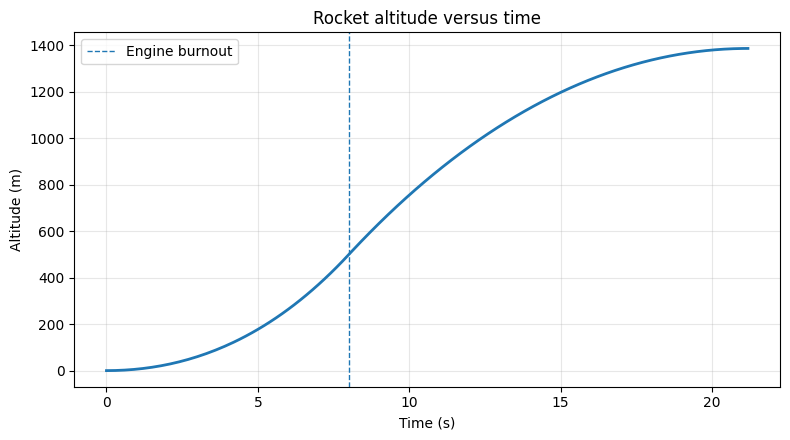

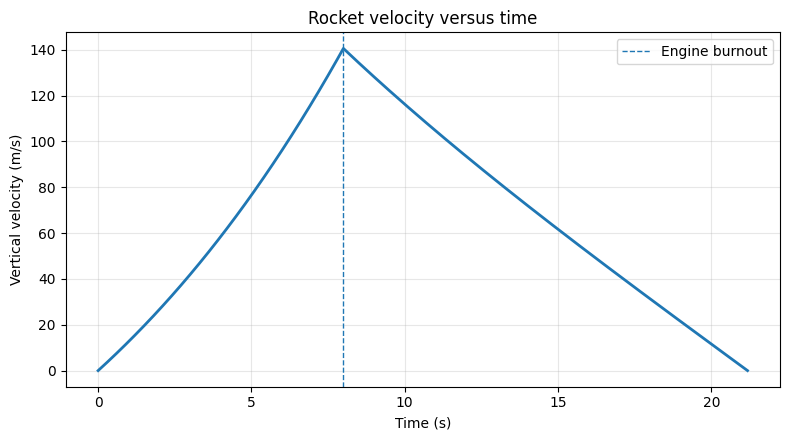

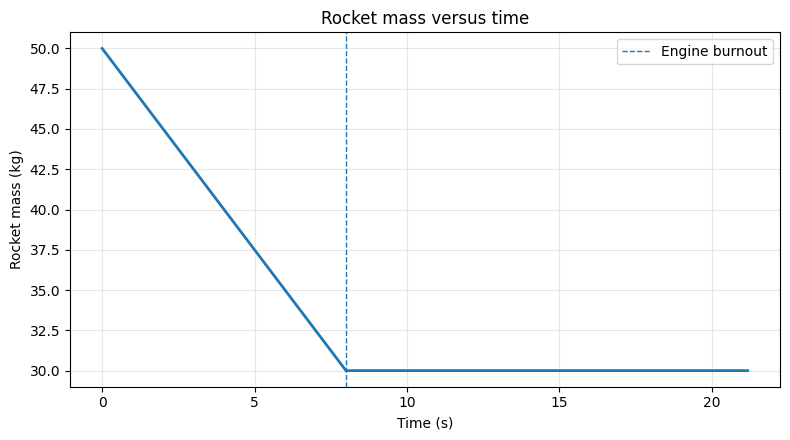

In [6]:
import matplotlib.pyplot as plt

for values, ylabel, label in [
    (heights, 'Altitude (m)', 'Rocket altitude versus time'),
    (velocities, 'Vertical velocity (m/s)', 'Rocket velocity versus time'),
    (masses, 'Rocket mass (kg)', 'Rocket mass versus time'),
]:
    fig, ax = plt.subplots(figsize=(8, 4.5))
    ax.plot(times, values, linewidth=2)
    ax.axvline(p.burn_time, linestyle='--', linewidth=1, label='Engine burnout')
    ax.set(xlabel='Time (s)', ylabel=ylabel, title=label)
    ax.grid(True, alpha=0.3)
    ax.legend()
    fig.tight_layout()
    plt.show()


Independent verification: drag-only exact solution
     dt         |altitude error|   |velocity error|   height error ratio
   1.000        5.284929e-02   7.396440e-04        nan
   0.500        2.641074e-03   5.657936e-05     20.011
   0.250        1.464151e-04   3.666537e-06     18.038
   0.125        8.601948e-06   2.309796e-07     17.021
Expected error ratio on halving dt: approximately 16 (4th order).

Rocket apogee convergence (illustrative parameters):
    dt [s]      apogee [m]      time of apogee [s]
    0.3000      1386.659941         21.182077
    0.1500      1386.659941         21.182077
    0.0750      1386.659941         21.182077
    0.0375      1386.659941         21.182077


Saved rocket_trajectory.csv
